# B4 – Performance comparison (clean version)

**Protocol (fixed before looking at results)**
1. Unit = (bot, vignette); reference = the doctor's final line.
2. Labels: *top-1* and *top-3* match and *refusal*, first by an LLM judge (cached in `results/judgements.jsonl`, so no new paid calls unless rows are missing), then **manual labels override the judge** where present (`results/manual_labels.csv`).
3. Metrics: accuracy with 95 % Wilson CI, refusal rate, latency, tokens.
4. Paired inference on vignettes answered by all compared bots: Cochran's Q + exact McNemar per pair with Holm correction.
5. Three separate analyses: **B3 core-5** (5 bots), **B3 all-30** (4 hosted bots), **B2** (Llama-2 via Ollama, descriptive).

Safe to re-run: nothing is deleted; manual labels you typed are preserved. All tables are also written to `results/summary_tables.md`.

In [1]:
import sys, os, json, time, re, shutil
from pathlib import Path
from datetime import datetime

# run from the project root even if the notebook lives in notebooks/
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

from dotenv import load_dotenv; load_dotenv()
import numpy as np, pandas as pd
from IPython.display import display
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

from vignettes import load_vignettes, sample_vignettes
from protocol import run_case
import store, metrics, clients

RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
VIGNETTES = load_vignettes("data/Clinical_Vignettes_26_27.txt")
# same call as notebook 03 -> same sample. DO NOT change these numbers.
SAMPLE = sample_vignettes(VIGNETTES, 5, 25, 2026)
CORE = [v for v in SAMPLE if v["set"] == "core"]
assert [v["id"] for v in CORE] == [15, 40, 64, 65, 82], "sample changed: check seed / N_CORE / N_EXTRA"
print(len(VIGNETTES), "clean vignettes | core ids:", [v["id"] for v in CORE])

117 clean vignettes | core ids: [15, 40, 64, 65, 82]


## 1. Configuration

In [2]:
MODE = "single"
JUDGE_SLUG = "openai/gpt-4o-mini"        # same as before: judge labels are cached for this judge
HOSTED = ["gemini", "chatgpt", "claude", "deepseek"]
B3_BOTS = HOSTED + ["local-qwen2.5-1.5b"]
B2_BOTS = ["llama2-7b-ollama", "llama2-13b-ollama"]
B2_SPACE_LEGACY = ["llama2-7b", "llama2-13b"]   # optional, supplementary (HF Space API); ignored if absent
ALL_BOTS = B3_BOTS + B2_BOTS + B2_SPACE_LEGACY

ALLOW_JUDGE_CALLS = True     # needed only if some rows have no cached judgement (costs cents)
APPLY_DRAFT = True           # fill EMPTY manual labels from results/manual_labels_core_DRAFT.csv
                             # kappa is a real human check only after YOU review those labels

## 2. Load runs and check coverage

In [3]:
runs = pd.DataFrame(store.load_runs())
runs = runs[(runs["mode"] == MODE) & runs["bot"].isin(ALL_BOTS)].drop_duplicates(["bot", "vignette_id"]).copy()
runs["gold"] = runs["vignette_id"].map({v["id"]: v["gold"] for v in VIGNETTES})
cov = runs.groupby(["bot", "set"]).size().unstack(fill_value=0).reindex(ALL_BOTS).fillna(0).astype(int)
display(cov)
exp = {b: (5, 25) for b in HOSTED}; exp["local-qwen2.5-1.5b"] = (5, 0)
exp.update({b: (5, 0) for b in B2_BOTS}); exp.update({"llama2-7b": (5, 0), "llama2-13b": (3, 0)})
for b, (c, e) in exp.items():
    if b in cov.index and (cov.loc[b, "core"], cov.loc[b, "extra"] if "extra" in cov.columns else 0) != (c, e):
        print(f"WARNING {b}: expected core={c}, extra={e}, found {tuple(cov.loc[b])}")

set,core,extra
bot,,
gemini,5,25
chatgpt,5,25
claude,5,25
deepseek,5,25
local-qwen2.5-1.5b,5,0
llama2-7b-ollama,5,0
llama2-13b-ollama,5,0
llama2-7b,5,0
llama2-13b,3,0


## 3. LLM-judge labels (cached)

In [4]:
JF = RESULTS / "judgements.jsonl"
cache = {}
if JF.exists():
    for l in JF.read_text(encoding="utf-8").splitlines():
        if l.strip():
            j = json.loads(l); cache[(j["bot"], j["vignette_id"])] = j
todo = [r for _, r in runs.iterrows() if (r["bot"], r["vignette_id"]) not in cache]
print(f"{len(cache)} cached judgements, {len(todo)} rows need judging")
if todo:
    if not ALLOW_JUDGE_CALLS:
        raise SystemExit("rows need judging but ALLOW_JUDGE_CALLS = False")
    judge_fn = clients.make_openrouter(JUDGE_SLUG, temperature=0.0, max_tokens=200)
    for r in todo:
        j = {"bot": r["bot"], "vignette_id": int(r["vignette_id"]), "judge": JUDGE_SLUG,
             **metrics.judge_answer(judge_fn, r["gold"], r["final_text"])}
        cache[(r["bot"], r["vignette_id"])] = j
        with JF.open("a", encoding="utf-8") as f: f.write(json.dumps(j) + "\n")
J = pd.DataFrame(cache.values()).drop(columns="judge")
df = runs.merge(J, on=["bot", "vignette_id"], how="left")
bad = df[df[["top1", "top3", "refusal"]].isna().any(axis=1)]
print("rows with unparsed judge output:", len(bad))
if len(bad): display(bad[["bot", "vignette_id"]])

143 cached judgements, 0 rows need judging
rows with unparsed judge output: 0


## 4. Manual labels (sync, never overwrite)
Creates or **updates** `results/manual_labels.csv`: adds any missing (bot, vignette) rows, keeps labels already there, and fills only *empty* cells from the draft file when `APPLY_DRAFT = True`.

In [5]:
MANUAL = RESULTS / "manual_labels.csv"          # a path (string-like), never reassigned
DRAFT = RESULTS / "manual_labels_core_DRAFT.csv"

base = df[["bot", "vignette_id", "set", "gold", "final_text", "top1", "top3"]].copy()
if MANUAL.exists():
    old = pd.read_csv(MANUAL)[["bot", "vignette_id", "manual_top1", "manual_top3"]]
else:
    old = pd.DataFrame(columns=["bot", "vignette_id", "manual_top1", "manual_top3"])
man = base.merge(old, on=["bot", "vignette_id"], how="left")
if APPLY_DRAFT:
    if DRAFT.exists():
        d = pd.read_csv(DRAFT).rename(columns={"manual_top1": "d1", "manual_top3": "d3"})
        man = man.merge(d[["bot", "vignette_id", "d1", "d3"]], on=["bot", "vignette_id"], how="left")
        man["manual_top1"] = man["manual_top1"].fillna(man["d1"])
        man["manual_top3"] = man["manual_top3"].fillna(man["d3"])
        man = man.drop(columns=["d1", "d3"])
    else:
        print("draft file not found in results/: copy manual_labels_core_DRAFT.csv there (or set APPLY_DRAFT=False)")
man.to_csv(MANUAL, index=False)
print(f"{len(man)} rows in {MANUAL}; labelled top1: {man.manual_top1.notna().sum()}, top3: {man.manual_top3.notna().sum()}")

143 rows in results/manual_labels.csv; labelled top1: 43, top3: 43


## 5. Judge vs manual agreement

In [6]:
def agreement(m, label):
    x = m.dropna(subset=[f"manual_{label}"])
    h, j = x[f"manual_{label}"].astype(int), x[label].astype(int)
    kappa = np.nan
    if len(x) and (len(set(h)) > 1 or len(set(j)) > 1):
        kappa = metrics.kappa(h, j)[0]
    return {"label": label, "n_labelled": len(x), "agree_%": round(100 * (h == j).mean(), 1) if len(x) else np.nan,
            "kappa": round(kappa, 3) if kappa == kappa else np.nan}
AG = pd.DataFrame([agreement(man, l) for l in ("top1", "top3")])
display(AG)
dis = man[(man.manual_top1.notna() & (man.manual_top1 != man.top1)) | (man.manual_top3.notna() & (man.manual_top3 != man.top3))]
print("rows where manual and judge disagree (manual overrides the judge below):")
display(dis[["bot", "vignette_id", "top1", "manual_top1", "top3", "manual_top3"]])

,label,n_labelled,agree_%,kappa
0,top1,43,100.0,1.000
1,top3,43,97.7,0.927


rows where manual and judge disagree (manual overrides the judge below):


,bot,vignette_id,top1,manual_top1,top3,manual_top3
130,llama2-13b-ollama,64,0,0.0,1,0.0


In [7]:
# final labels = manual where available, else judge
df = df.merge(man[["bot", "vignette_id", "manual_top1", "manual_top3"]], on=["bot", "vignette_id"], how="left")
df = df.rename(columns={"top1": "judge_top1", "top3": "judge_top3"})
df["top1"] = df["manual_top1"].fillna(df["judge_top1"]).astype(int)
df["top3"] = df["manual_top3"].fillna(df["judge_top3"]).astype(int)
df["top3"] = np.maximum(df["top3"], df["top1"])     # top-1 correct implies top-3 correct
print("final labels ready:", len(df), "rows")

final labels ready: 143 rows


## 6. Analysis helpers

In [8]:
import matplotlib; import matplotlib.pyplot as plt
MD = []   # markdown collected for results/summary_tables.md

def md_table(d, nd=3):
    d = d.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].map(lambda x: "" if pd.isna(x) else f"{x:.{nd}f}")
    rows = ["| " + " | ".join(map(str, r)) + " |" for r in d.values.tolist()]
    return "\n".join(["| " + " | ".join(map(str, d.columns)) + " |", "|" + "---|" * len(d.columns)] + rows)

def show(title, d, tag, nd=3):
    print(f"\n### {title}"); display(d.round(nd)); d.to_csv(RESULTS / f"{tag}.csv", index=False)
    MD.append(f"#### {title}\n\n" + md_table(d, nd) + "\n")

def analyse(d, tag, title):
    MD.append(f"### {title}\n")
    print("=" * 90 + f"\n{title}  |  bots: {sorted(d.bot.unique())}  |  rows: {len(d)}")
    for lab in ("top1", "top3"):
        t = metrics.accuracy_table(d, lab)
        t["ci95"] = t.apply(lambda r: f"{r.ci95_low:.3f}–{r.ci95_high:.3f}", axis=1)
        show(f"{lab} accuracy", t[["bot", "n", "correct", "accuracy", "ci95"]], f"{tag}_acc_{lab}")
    w = metrics.wide(d, "top1"); nb_, nv = w.shape[1], len(w)
    print(f"paired vignettes (answered by every bot): {nv}")
    if nb_ >= 3 and nv >= 2:
        q = metrics.cochran(w)
        if q:
            msg = f"Cochran's Q (top-1): Q = {q['Q']:.2f}, df = {q['df']}, p = {q['p']:.3f} ({nb_} bots, {nv} paired vignettes)"
            print(msg); MD.append(msg + "\n")
    if nb_ >= 2 and nv >= 2:
        pm = metrics.pairwise_mcnemar(w); show("pairwise exact McNemar (top-1, Holm)", pm, f"{tag}_mcnemar", 4)
    e = metrics.efficiency_table(d); show("latency / tokens / refusals", e, f"{tag}_efficiency", 2)
    t = metrics.accuracy_table(d, "top1")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(t["bot"], t["accuracy"], yerr=[t["accuracy"] - t["ci95_low"], t["ci95_high"] - t["accuracy"]], capsize=4)
    ax.set_ylabel("top-1 accuracy"); ax.set_ylim(0, 1.05); ax.set_title(title); plt.xticks(rotation=30, ha="right")
    plt.tight_layout(); fig.savefig(RESULTS / f"{tag}_top1.png", dpi=150); plt.show()

## 7. B3 – five bots, core vignettes (n = 5)

B3 core vignettes (n = 5 per bot)  |  bots: ['chatgpt', 'claude', 'deepseek', 'gemini', 'local-qwen2.5-1.5b']  |  rows: 25

### top1 accuracy


,bot,n,correct,accuracy,ci95
0,deepseek,5,5,1.0,0.566–1.000
1,chatgpt,5,4,0.8,0.376–0.964
2,claude,5,4,0.8,0.376–0.964
3,gemini,5,3,0.6,0.231–0.882
4,local-qwen2.5-1.5b,5,0,0.0,0.000–0.434



### top3 accuracy


,bot,n,correct,accuracy,ci95
0,chatgpt,5,5,1.0,0.566–1.000
1,claude,5,5,1.0,0.566–1.000
2,deepseek,5,5,1.0,0.566–1.000
3,gemini,5,4,0.8,0.376–0.964
4,local-qwen2.5-1.5b,5,2,0.4,0.118–0.769


paired vignettes (answered by every bot): 5
Cochran's Q (top-1): Q = 12.33, df = 4, p = 0.015 (5 bots, 5 paired vignettes)

### pairwise exact McNemar (top-1, Holm)


,A,B,A_only_correct,B_only_correct,p_raw,p_holm
0,chatgpt,claude,1,1,1.0000,1.000
1,chatgpt,deepseek,0,1,1.0000,1.000
2,chatgpt,gemini,1,0,1.0000,1.000
3,chatgpt,local-qwen2.5-1.5b,4,0,0.1250,1.000
4,claude,deepseek,0,1,1.0000,1.000
5,claude,gemini,1,0,1.0000,1.000
6,claude,local-qwen2.5-1.5b,4,0,0.1250,1.000
7,deepseek,gemini,2,0,0.5000,1.000
8,deepseek,local-qwen2.5-1.5b,5,0,0.0625,0.625
9,gemini,local-qwen2.5-1.5b,3,0,0.2500,1.000



### latency / tokens / refusals


,bot,latency_mean_s,latency_median_s,completion_tokens_mean,refusal_rate
0,chatgpt,2.55,2.54,117.8,0.0
1,claude,5.03,5.12,190.8,0.0
2,deepseek,6.33,6.36,103.4,0.0
3,gemini,2.34,1.84,144.8,0.0
4,local-qwen2.5-1.5b,39.12,39.56,94.8,0.0


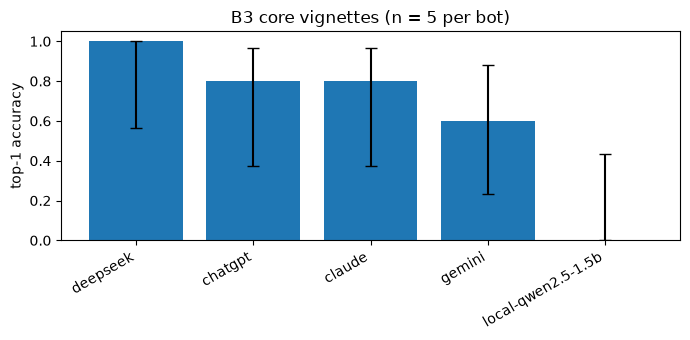

In [9]:
core_b3 = df[(df["set"] == "core") & df["bot"].isin(B3_BOTS)]
analyse(core_b3, "B3_core5", "B3 core vignettes (n = 5 per bot)")

In [10]:
# per-vignette top-1 matrix (1 = matches reference)
mat = core_b3.pivot_table(index="vignette_id", columns="bot", values="top1", aggfunc="first")[B3_BOTS]
display(mat); MD.append("#### per-vignette top-1 (B3 core)\n\n" + md_table(mat.reset_index().round(0).astype({c: int for c in mat.columns})) + "\n")

bot,gemini,chatgpt,claude,deepseek,local-qwen2.5-1.5b
vignette_id,,,,,
15,0,1,0,1,0
40,1,1,1,1,0
64,0,0,1,1,0
65,1,1,1,1,0
82,1,1,1,1,0


## 8. B3 – four hosted bots, all 30 vignettes

vignettes per hosted bot: {'chatgpt': 30, 'claude': 30, 'deepseek': 30, 'gemini': 30}
B3 hosted bots, core + extra (n = 30 per bot)  |  bots: ['chatgpt', 'claude', 'deepseek', 'gemini']  |  rows: 120

### top1 accuracy


,bot,n,correct,accuracy,ci95
0,deepseek,30,26,0.867,0.703–0.947
1,chatgpt,30,24,0.800,0.627–0.905
2,claude,30,24,0.800,0.627–0.905
3,gemini,30,20,0.667,0.488–0.808



### top3 accuracy


,bot,n,correct,accuracy,ci95
0,deepseek,30,29,0.967,0.833–0.994
1,chatgpt,30,28,0.933,0.787–0.982
2,claude,30,27,0.900,0.744–0.965
3,gemini,30,27,0.900,0.744–0.965


paired vignettes (answered by every bot): 30
Cochran's Q (top-1): Q = 6.00, df = 3, p = 0.112 (4 bots, 30 paired vignettes)

### pairwise exact McNemar (top-1, Holm)


,A,B,A_only_correct,B_only_correct,p_raw,p_holm
0,chatgpt,claude,3,3,1.0000,1.0000
1,chatgpt,deepseek,1,3,0.6250,1.0000
2,chatgpt,gemini,5,1,0.2188,1.0000
3,claude,deepseek,2,4,0.6875,1.0000
4,claude,gemini,5,1,0.2188,1.0000
5,deepseek,gemini,8,2,0.1094,0.6562



### latency / tokens / refusals


,bot,latency_mean_s,latency_median_s,completion_tokens_mean,refusal_rate
0,chatgpt,2.48,2.35,116.37,0.0
1,claude,4.65,4.63,359.87,0.0
2,deepseek,3.83,2.69,99.50,0.0
3,gemini,1.41,1.18,138.37,0.0


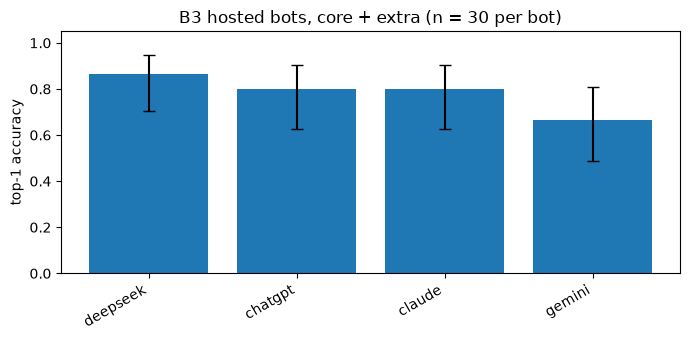

In [11]:
all_h = df[df["bot"].isin(HOSTED)]
full = all_h.groupby("bot").vignette_id.nunique()
print("vignettes per hosted bot:", full.to_dict())
analyse(all_h, "B3_all30", "B3 hosted bots, core + extra (n = 30 per bot)")

## 9. B2 – Llama-2 7B vs 13B (Ollama, descriptive)

B2 Llama-2 via Ollama (n = 5 per model)  |  bots: ['llama2-13b-ollama', 'llama2-7b-ollama']  |  rows: 10

### top1 accuracy


,bot,n,correct,accuracy,ci95
0,llama2-13b-ollama,5,2,0.4,0.118–0.769
1,llama2-7b-ollama,5,2,0.4,0.118–0.769



### top3 accuracy


,bot,n,correct,accuracy,ci95
0,llama2-13b-ollama,5,4,0.8,0.376–0.964
1,llama2-7b-ollama,5,3,0.6,0.231–0.882


paired vignettes (answered by every bot): 5

### pairwise exact McNemar (top-1, Holm)


,A,B,A_only_correct,B_only_correct,p_raw,p_holm
0,llama2-13b-ollama,llama2-7b-ollama,0,0,1.0,1.0



### latency / tokens / refusals


,bot,latency_mean_s,latency_median_s,completion_tokens_mean,refusal_rate
0,llama2-13b-ollama,74.78,66.35,220.0,0.0
1,llama2-7b-ollama,57.35,57.05,326.8,0.0


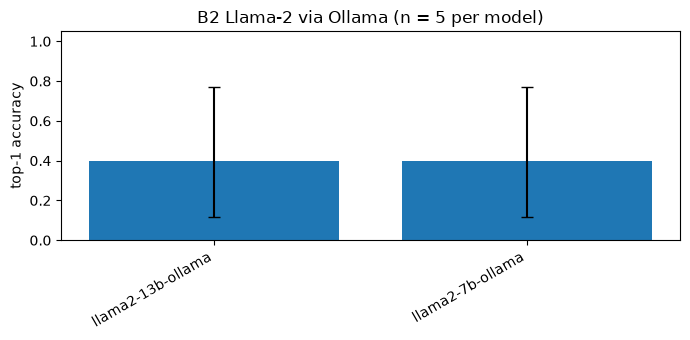

In [12]:
b2 = df[(df["set"] == "core") & df["bot"].isin(B2_BOTS)]
analyse(b2, "B2_ollama", "B2 Llama-2 via Ollama (n = 5 per model)")

B2 Llama-2 via HF Space API (supplementary)  |  bots: ['llama2-13b', 'llama2-7b']  |  rows: 8

### top1 accuracy


,bot,n,correct,accuracy,ci95
0,llama2-7b,5,2,0.4,0.118–0.769
1,llama2-13b,3,0,0.0,0.000–0.561



### top3 accuracy


,bot,n,correct,accuracy,ci95
0,llama2-7b,5,4,0.800,0.376–0.964
1,llama2-13b,3,2,0.667,0.208–0.939


paired vignettes (answered by every bot): 3

### pairwise exact McNemar (top-1, Holm)


,A,B,A_only_correct,B_only_correct,p_raw,p_holm
0,llama2-13b,llama2-7b,0,1,1.0,1.0



### latency / tokens / refusals


,bot,latency_mean_s,latency_median_s,completion_tokens_mean,refusal_rate
0,llama2-13b,8.50,7.38,0.0,0.0
1,llama2-7b,9.76,10.40,0.0,0.0


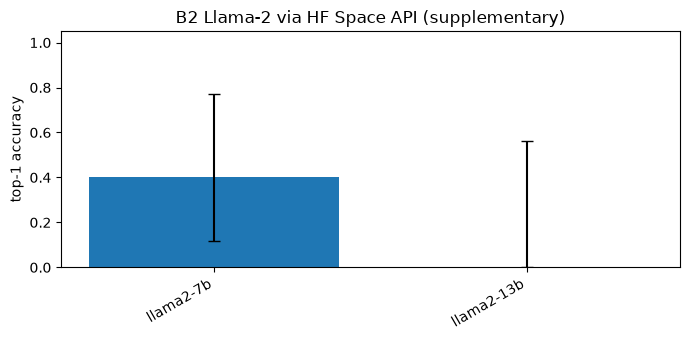

In [13]:
# optional: legacy HF Space rows (supplementary; 13B has only the 3 API vignettes in runs.jsonl)
sp = df[(df["set"] == "core") & df["bot"].isin(B2_SPACE_LEGACY)]
if len(sp):
    analyse(sp, "B2_space_legacy", "B2 Llama-2 via HF Space API (supplementary)")
else:
    print("no legacy Space rows")

## 10. Save everything

In [14]:
(RESULTS / "summary_tables.md").write_text("\n".join(MD), encoding="utf-8")
manifest = {"created": datetime.now().isoformat(timespec="seconds"), "judge": JUDGE_SLUG, "mode": MODE,
            "apply_draft": APPLY_DRAFT, "rows": int(len(df)),
            "labelled_rows": {"top1": int(man.manual_top1.notna().sum()), "top3": int(man.manual_top3.notna().sum())},
            "agreement": AG.to_dict("records")}
(RESULTS / "b4_manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")
df.drop(columns=["final_text"]).to_csv(RESULTS / "final_labels.csv", index=False)
print("saved: results/summary_tables.md, b4_manifest.json, final_labels.csv, B3_core5_*, B3_all30_*, B2_ollama_*")
print(json.dumps(manifest, indent=1))

saved: results/summary_tables.md, b4_manifest.json, final_labels.csv, B3_core5_*, B3_all30_*, B2_ollama_*
{
 "created": "2026-11-27T08:45:32",
 "judge": "openai/gpt-4o-mini",
 "mode": "single",
 "apply_draft": true,
 "rows": 143,
 "labelled_rows": {
  "top1": 43,
  "top3": 43
 },
 "agreement": [
  {
   "label": "top1",
   "n_labelled": 43,
   "agree_%": 100.0,
   "kappa": 1.0
  },
  {
   "label": "top3",
   "n_labelled": 43,
   "agree_%": 97.7,
   "kappa": 0.927
  }
 ]
}
